# SpaceX Falcon 9: Interactive Visual Analytics with Folium
Mark launch sites, show launch outcomes per site, and measure distances to nearby features.

*GitHub does not render Folium maps; static screenshots are shown under each map. Open in Jupyter or nbviewer for the interactive version.*

In [1]:
import folium, pandas as pd, requests, math
from folium.plugins import MarkerCluster, MousePosition
from folium.features import DivIcon
from IPython.display import Image, display
spacex_df = pd.read_csv("https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBM-DS0321EN-SkillsNetwork/datasets/spacex_launch_geo.csv")
spacex_df = spacex_df[["Launch Site", "Lat", "Long", "class"]]
spacex_df.head()

,Launch Site,Lat,Long,class
0,CCAFS LC-40,28.562302,-80.577356,0
1,CCAFS LC-40,28.562302,-80.577356,0
2,CCAFS LC-40,28.562302,-80.577356,0
3,CCAFS LC-40,28.562302,-80.577356,0
4,CCAFS LC-40,28.562302,-80.577356,0


## Task 1: Mark all launch sites on a map

In [2]:
launch_sites_df = spacex_df.groupby(["Launch Site"], as_index=False).first()[["Launch Site", "Lat", "Long"]]
launch_sites_df

,Launch Site,Lat,Long
0,CCAFS LC-40,28.562302,-80.577356
1,CCAFS SLC-40,28.563197,-80.576820
2,KSC LC-39A,28.573255,-80.646895
3,VAFB SLC-4E,34.632834,-120.610745


In [3]:
nasa_coordinate = [29.559684888503615, -95.0830971930759]
site_map = folium.Map(location=nasa_coordinate, zoom_start=5)
for _, r in launch_sites_df.iterrows():
    c = [r["Lat"], r["Long"]]
    folium.Circle(c, radius=1000, color="#d35400", fill=True).add_child(folium.Popup(r["Launch Site"])).add_to(site_map)
    folium.map.Marker(c, icon=DivIcon(icon_size=(20, 20), icon_anchor=(0, 0), html=f"<div style='font-size: 12; color:#d35400;'><b>{r['Launch Site']}</b></div>")).add_to(site_map)
site_map

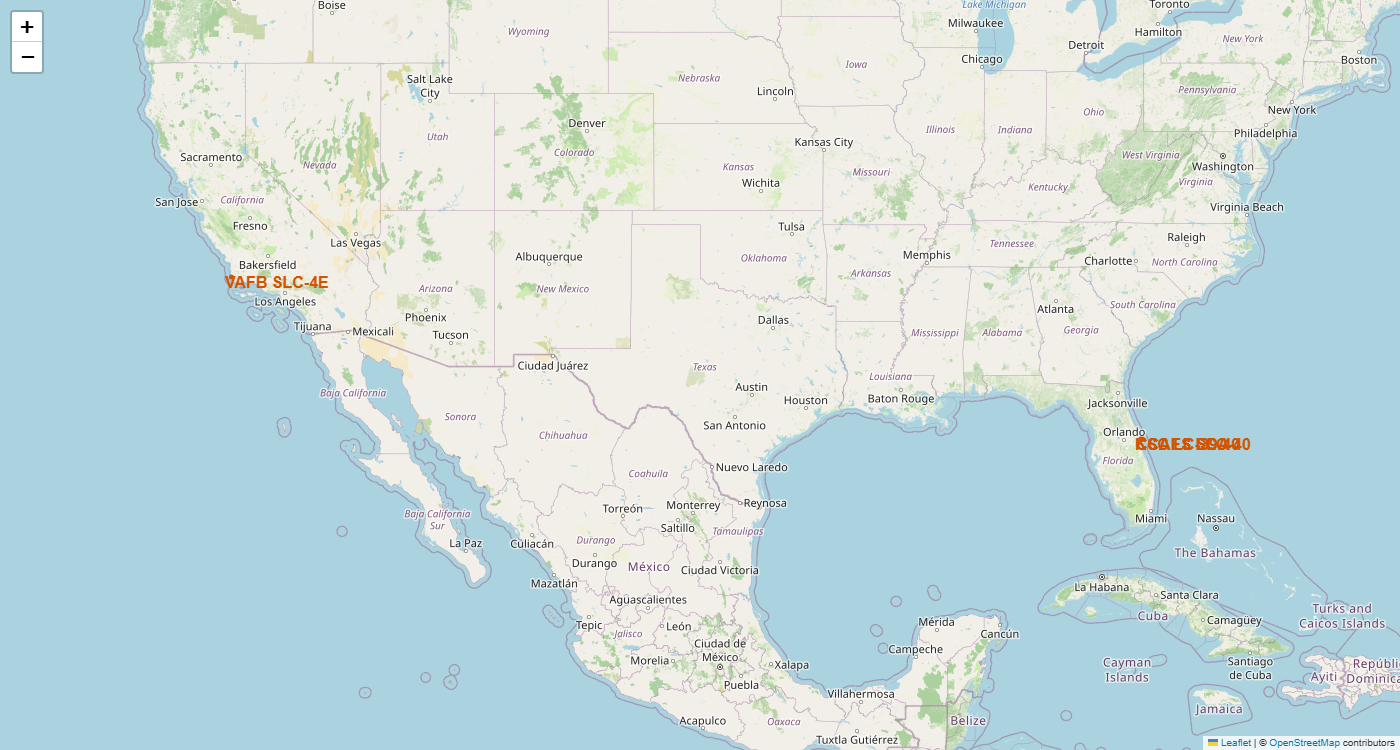

In [4]:
display(Image("../outputs/maps/map_all.png", width=900))

All launch sites are near the coast and in the far south of the US, as close to the equator as the mainland allows.

## Task 2: Mark the success/failed launches for each site

In [5]:
marker_cluster = MarkerCluster()
spacex_df["marker_color"] = spacex_df["class"].map({1: "green", 0: "red"})
site_map.add_child(marker_cluster)
for _, r in spacex_df.iterrows():
    folium.Marker([r["Lat"], r["Long"]], icon=folium.Icon(color="white", icon_color=r["marker_color"])).add_to(marker_cluster)
site_map

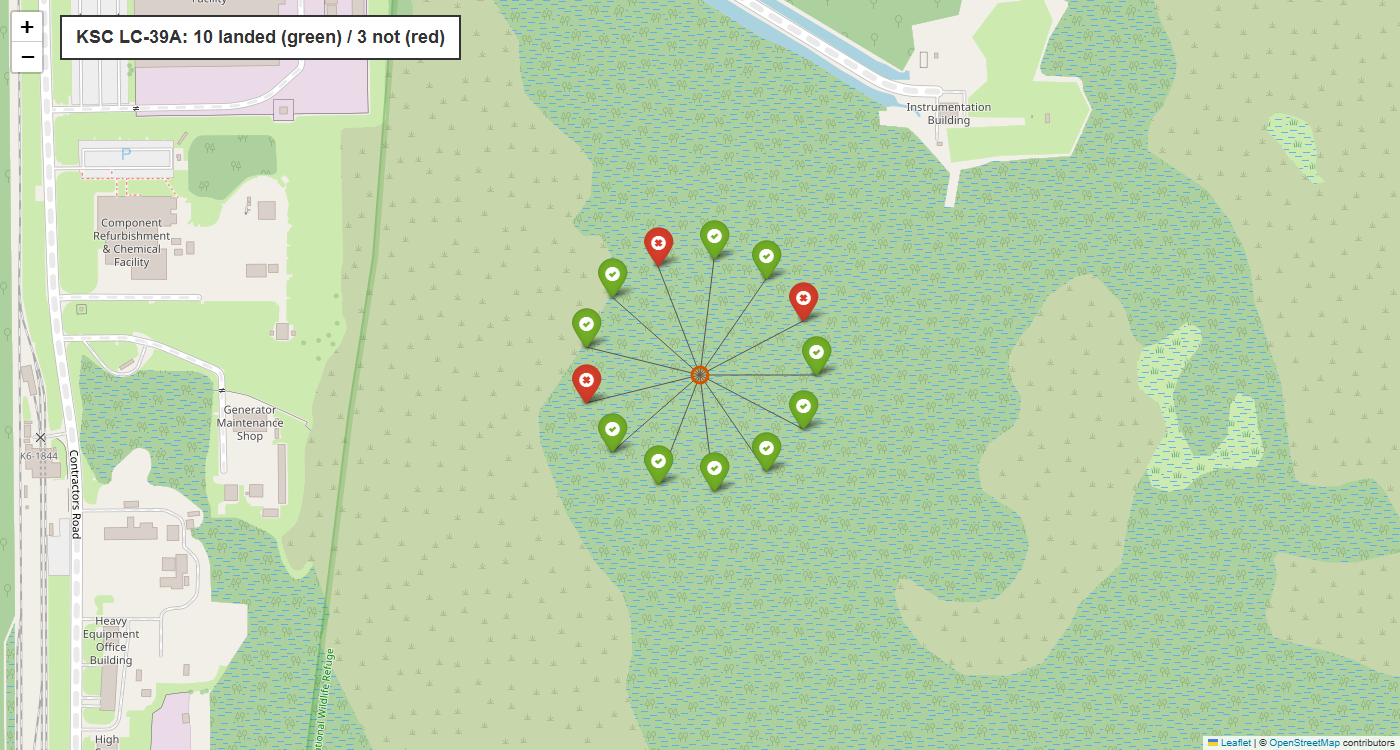

,count,sum,mean
Launch Site,,,
CCAFS LC-40,26,7,0.269231
CCAFS SLC-40,7,3,0.428571
KSC LC-39A,13,10,0.769231
VAFB SLC-4E,10,4,0.400000


In [6]:
display(Image("../outputs/maps/map_ksc.png", width=900))
spacex_df.groupby("Launch Site")["class"].agg(["count", "sum", "mean"])

KSC LC-39A has the highest share of green (successful) markers.

## Task 3: Calculate the distances between a launch site and its proximities

In [7]:
formatter = "function(num) {return L.Util.formatNum(num, 5);};"
site_map.add_child(MousePosition(position="topright", separator=" Long: ", empty_string="NaN", lng_first=False, num_digits=20, prefix="Lat:", lat_formatter=formatter, lng_formatter=formatter))

def calculate_distance(lat1, lon1, lat2, lon2):
    R = 6373.0
    lat1, lon1, lat2, lon2 = map(math.radians, [lat1, lon1, lat2, lon2])
    dlon, dlat = lon2 - lon1, lat2 - lat1
    a = math.sin(dlat / 2)**2 + math.cos(lat1) * math.cos(lat2) * math.sin(dlon / 2)**2
    return R * 2 * math.atan2(math.sqrt(a), math.sqrt(1 - a))

Nearest points were read with MousePosition and checked against OpenStreetMap (coordinates below).

In [8]:
launch_site = (28.563197, -80.576820)  # CCAFS SLC-40
points = {"coastline": (28.5654777, -80.5683199), "railway": (28.5634058, -80.5767773),
          "highway (NASA Parkway East)": (28.5139133, -80.6126927), "city (Titusville)": (28.6126236, -80.8079545)}
dist_map = folium.Map(location=[28.55, -80.69], zoom_start=11)
folium.CircleMarker(launch_site, radius=8, color="#d35400", fill=True).add_to(dist_map)
for name, p in points.items():
    d = calculate_distance(*launch_site, *p)
    print(f"{name}: {d:.2f} km")
    folium.Marker(p, icon=DivIcon(icon_size=(20, 20), icon_anchor=(0, 0), html=f"<div style='font-size: 12; color:#1f4e79;'><b>{d:.2f} KM</b></div>")).add_to(dist_map)
    folium.PolyLine([launch_site, p], weight=2).add_to(dist_map)
dist_map

coastline: 0.87 km
railway: 0.02 km
highway (NASA Parkway East): 6.51 km
city (Titusville): 23.23 km


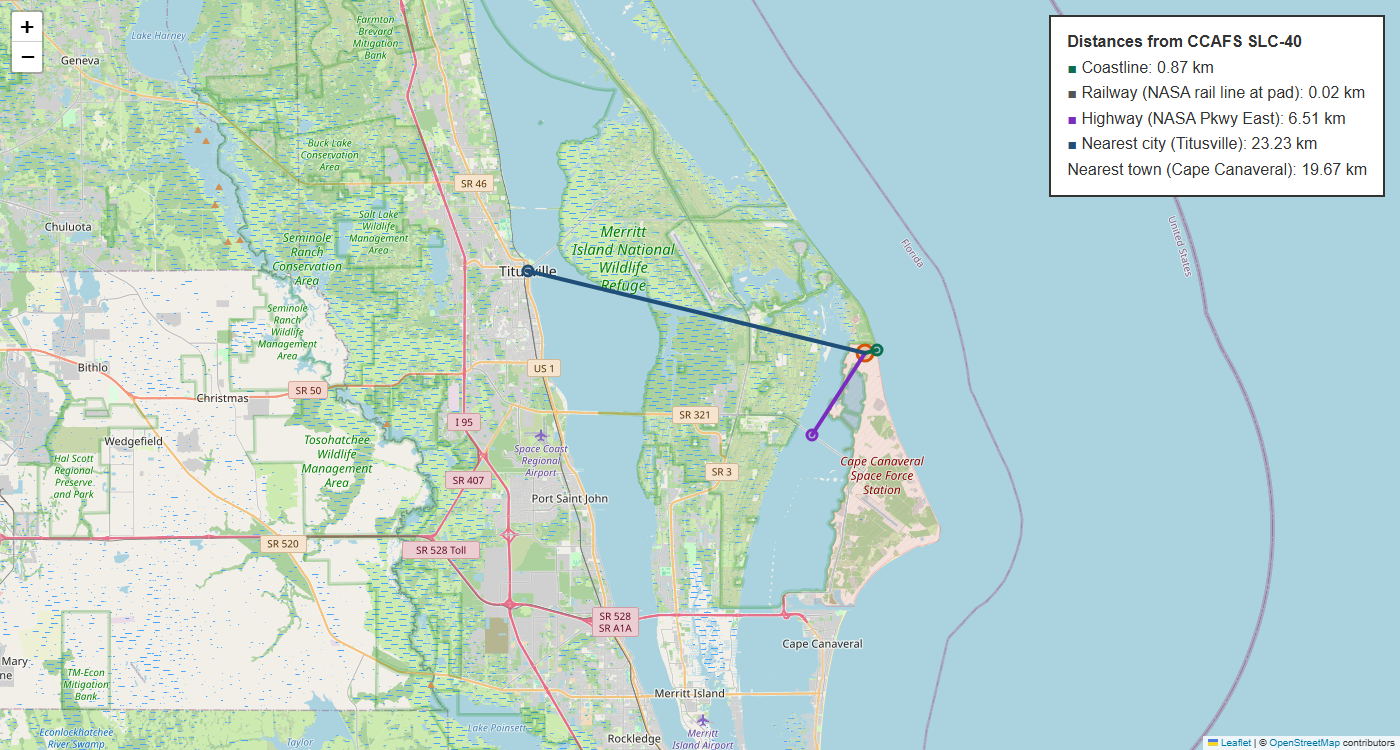

In [9]:
display(Image("../outputs/maps/map_prox.png", width=900))

**Findings:** launch sites are close to the coastline (~0.9 km), railways and highways (logistics), and keep a distance from cities (~23 km to Titusville) for safety.